In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
features = pd.read_csv("features.csv")
stores = pd.read_csv("stores.csv")

In [3]:
print("Train dataset:", train.shape)
print("Test dataset:", test.shape)
print("Features dataset:", features.shape)
print("Stores dataset:", stores.shape)

Train dataset: (421570, 5)
Test dataset: (115064, 4)
Features dataset: (8190, 12)
Stores dataset: (45, 3)


In [4]:
train.head()


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [5]:
train.columns


Index(['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday'], dtype='object')

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  object 
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(1)
memory usage: 13.3+ MB


In [7]:
print("Missing values in TRAIN:")
print(train.isnull().sum())

print("\nMissing values in FEATURES:")
print(features.isnull().sum())

print("\nMissing values in STORES:")
print(stores.isnull().sum())

print("\nMissing values in TEST:")
print(test.isnull().sum())

Missing values in TRAIN:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

Missing values in FEATURES:
Store              0
Date               0
Temperature        0
Fuel_Price         0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64

Missing values in STORES:
Store    0
Type     0
Size     0
dtype: int64

Missing values in TEST:
Store        0
Dept         0
Date         0
IsHoliday    0
dtype: int64


In [8]:
markdown_cols = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

features[markdown_cols] = features[markdown_cols].fillna(0)

In [9]:
features[markdown_cols].isnull().sum()

MarkDown1    0
MarkDown2    0
MarkDown3    0
MarkDown4    0
MarkDown5    0
dtype: int64

In [10]:
features["CPI"] = features["CPI"].ffill().bfill()
features["Unemployment"] = features["Unemployment"].ffill().bfill()

In [11]:
features[["CPI", "Unemployment"]].isnull().sum()

CPI             0
Unemployment    0
dtype: int64

In [12]:
features.isnull().sum()

Store           0
Date            0
Temperature     0
Fuel_Price      0
MarkDown1       0
MarkDown2       0
MarkDown3       0
MarkDown4       0
MarkDown5       0
CPI             0
Unemployment    0
IsHoliday       0
dtype: int64

In [13]:
train["Date"] = pd.to_datetime(train["Date"])
test["Date"] = pd.to_datetime(test["Date"])
features["Date"] = pd.to_datetime(features["Date"])

In [14]:
train.dtypes

Store                    int64
Dept                     int64
Date            datetime64[ns]
Weekly_Sales           float64
IsHoliday                 bool
dtype: object

In [15]:
df = pd.merge(
    train,
    features,
    on=["Store", "Date", "IsHoliday"],
    how="left"
)

In [16]:
df = pd.merge(
    df,
    stores,
    on="Store",
    how="left"
)

In [17]:
print("Final dataset shape:", df.shape)

Final dataset shape: (421570, 16)


In [18]:
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,A,151315


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[ns]
 3   Weekly_Sales  421570 non-null  float64       
 4   IsHoliday     421570 non-null  bool          
 5   Temperature   421570 non-null  float64       
 6   Fuel_Price    421570 non-null  float64       
 7   MarkDown1     421570 non-null  float64       
 8   MarkDown2     421570 non-null  float64       
 9   MarkDown3     421570 non-null  float64       
 10  MarkDown4     421570 non-null  float64       
 11  MarkDown5     421570 non-null  float64       
 12  CPI           421570 non-null  float64       
 13  Unemployment  421570 non-null  float64       
 14  Type          421570 non-null  object        
 15  Size          421

In [20]:
df["Year"] = df["Date"].dt.year

In [21]:
df["Month"] = df["Date"].dt.month

In [22]:
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)

In [23]:
df["Day"] = df["Date"].dt.day

In [24]:
df["Quarter"] = df["Date"].dt.quarter

In [25]:
df[["Date", "Year", "Month", "Week", "Day", "Quarter"]].head()


,Date,Year,Month,Week,Day,Quarter
0,2010-02-05,2010,2,5,5,1
1,2010-02-12,2010,2,6,12,1
2,2010-02-19,2010,2,7,19,1
3,2010-02-26,2010,2,8,26,1
4,2010-03-05,2010,3,9,5,1


In [26]:
yearly_sales = df.groupby("Year")["Weekly_Sales"].sum()
yearly_sales

Year
2010    2.288886e+09
2011    2.448200e+09
2012    2.000133e+09
Name: Weekly_Sales, dtype: float64

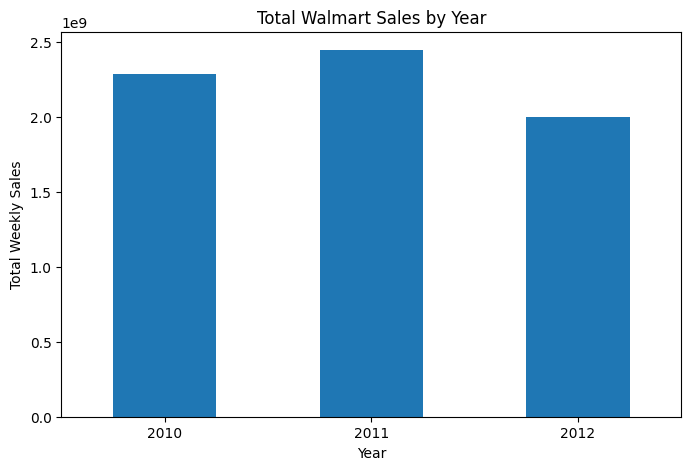

In [27]:
plt.figure(figsize=(8,5))
yearly_sales.plot(kind="bar")
plt.title("Total Walmart Sales by Year")
plt.xlabel("Year")
plt.ylabel("Total Weekly Sales")
plt.xticks(rotation=0)
plt.show()

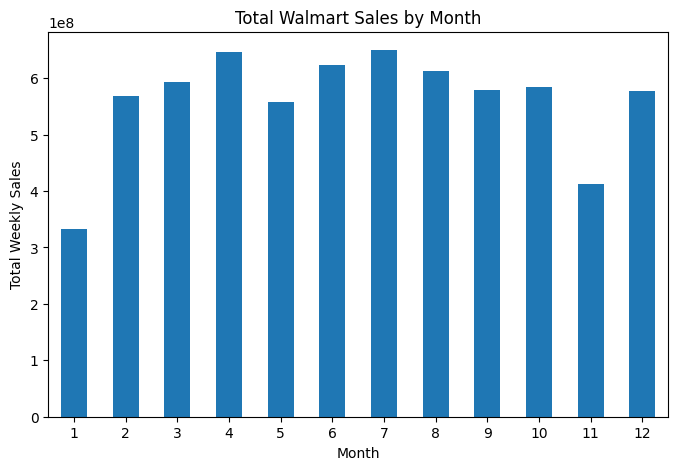

In [28]:
monthly_sales = df.groupby("Month")["Weekly_Sales"].sum()
plt.figure(figsize=(8,5))
monthly_sales.plot(kind="bar")
plt.title("Total Walmart Sales by Month")
plt.xlabel("Month")
plt.ylabel("Total Weekly Sales")
plt.xticks(range(12), range(1, 13), rotation=0)
plt.show()

In [29]:
holiday_sales = df.groupby("IsHoliday")["Weekly_Sales"].mean()
holiday_sales

IsHoliday
False    15901.445069
True     17035.823187
Name: Weekly_Sales, dtype: float64

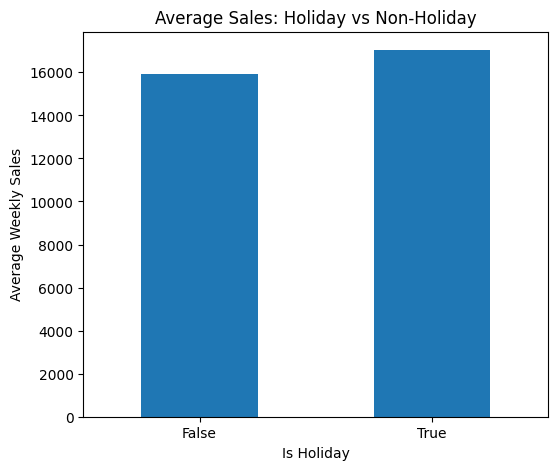

In [30]:
plt.figure(figsize=(6,5))
holiday_sales.plot(kind="bar")
plt.title("Average Sales: Holiday vs Non-Holiday")
plt.xlabel("Is Holiday")
plt.ylabel("Average Weekly Sales")
plt.xticks(rotation=0)
plt.show()

In [31]:
store_sales = df.groupby("Store")["Weekly_Sales"].sum().sort_values(ascending=False)
store_sales.head(10)

Store
20    3.013978e+08
4     2.995440e+08
14    2.889999e+08
13    2.865177e+08
2     2.753824e+08
10    2.716177e+08
27    2.538559e+08
6     2.237561e+08
1     2.224028e+08
39    2.074455e+08
Name: Weekly_Sales, dtype: float64

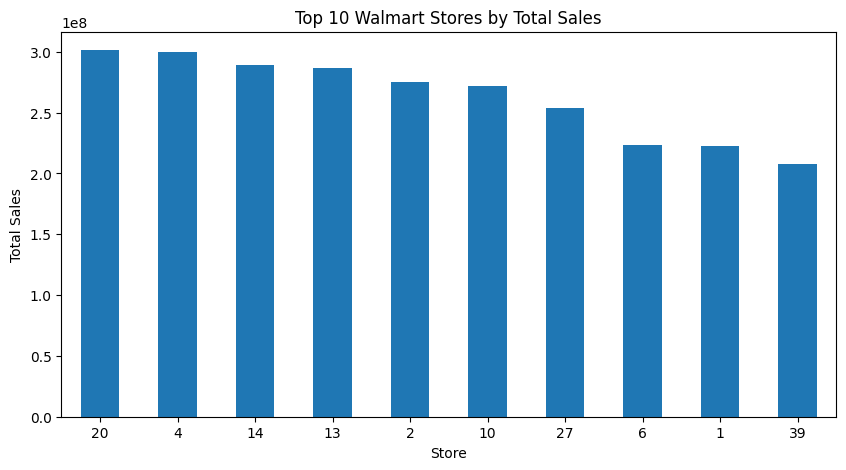

In [32]:
plt.figure(figsize=(10, 5))
store_sales.head(10).plot(kind="bar")
plt.title("Top 10 Walmart Stores by Total Sales")
plt.xlabel("Store")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

In [33]:
dept_sales = df.groupby("Dept")["Weekly_Sales"].sum().sort_values(ascending=False)
dept_sales.head(10)

Dept
92    4.839433e+08
95    4.493202e+08
38    3.931181e+08
72    3.057252e+08
90    2.910685e+08
40    2.889360e+08
2     2.806112e+08
91    2.167817e+08
13    1.973216e+08
8     1.942808e+08
Name: Weekly_Sales, dtype: float64

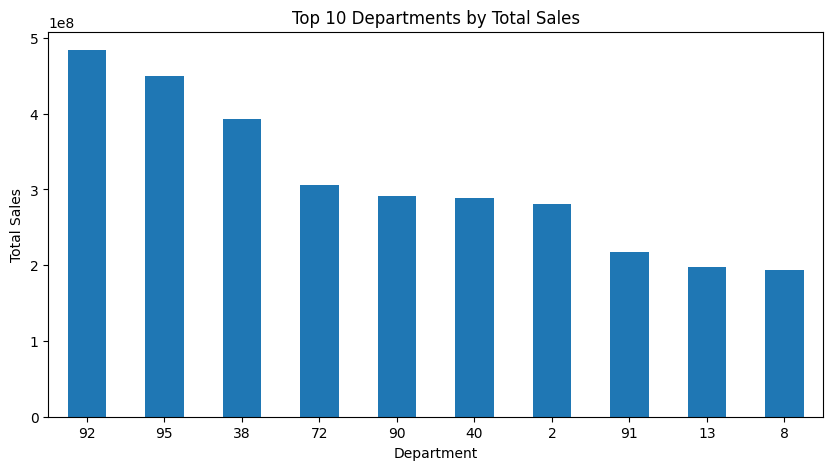

In [34]:
plt.figure(figsize=(10, 5))
dept_sales.head(10).plot(kind="bar")
plt.title("Top 10 Departments by Total Sales")
plt.xlabel("Department")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

In [35]:
type_sales = df.groupby("Type")["Weekly_Sales"].sum()
type_sales

Type
A    4.331015e+09
B    2.000701e+09
C    4.055035e+08
Name: Weekly_Sales, dtype: float64

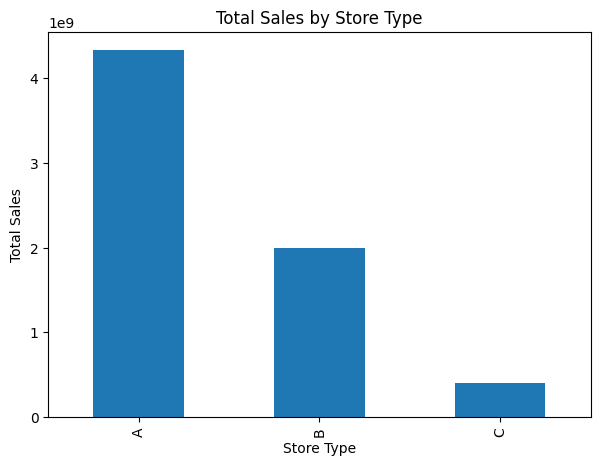

In [58]:
plt.figure(figsize=(7, 5))

type_sales.plot(kind="bar")

plt.title("Total Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Total Sales")
plt.show()

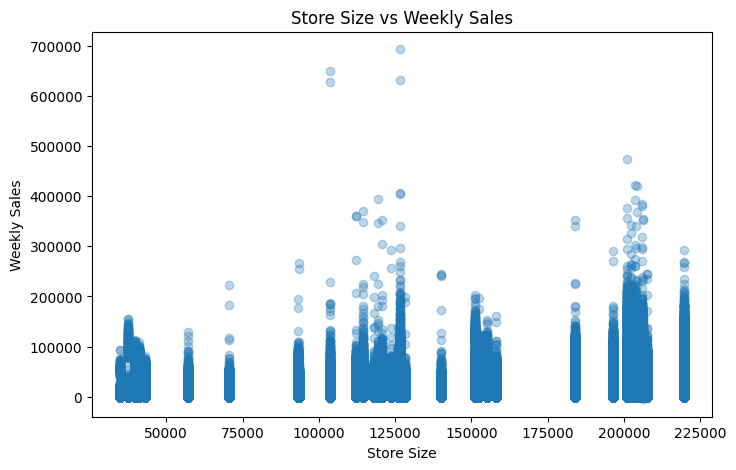

In [37]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Size"], df["Weekly_Sales"], alpha=0.3)
plt.title("Store Size vs Weekly Sales")
plt.xlabel("Store Size")
plt.ylabel("Weekly Sales")
plt.show()

In [38]:
numeric_cols = [
    "Store",
    "Dept",
    "Weekly_Sales",
    "Temperature",
    "Fuel_Price",
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5",
    "CPI",
    "Unemployment",
    "Size",
    "Year",
    "Month",
    "Week",
    "Day",
    "Quarter"
]

In [39]:
correlation = df[numeric_cols].corr()

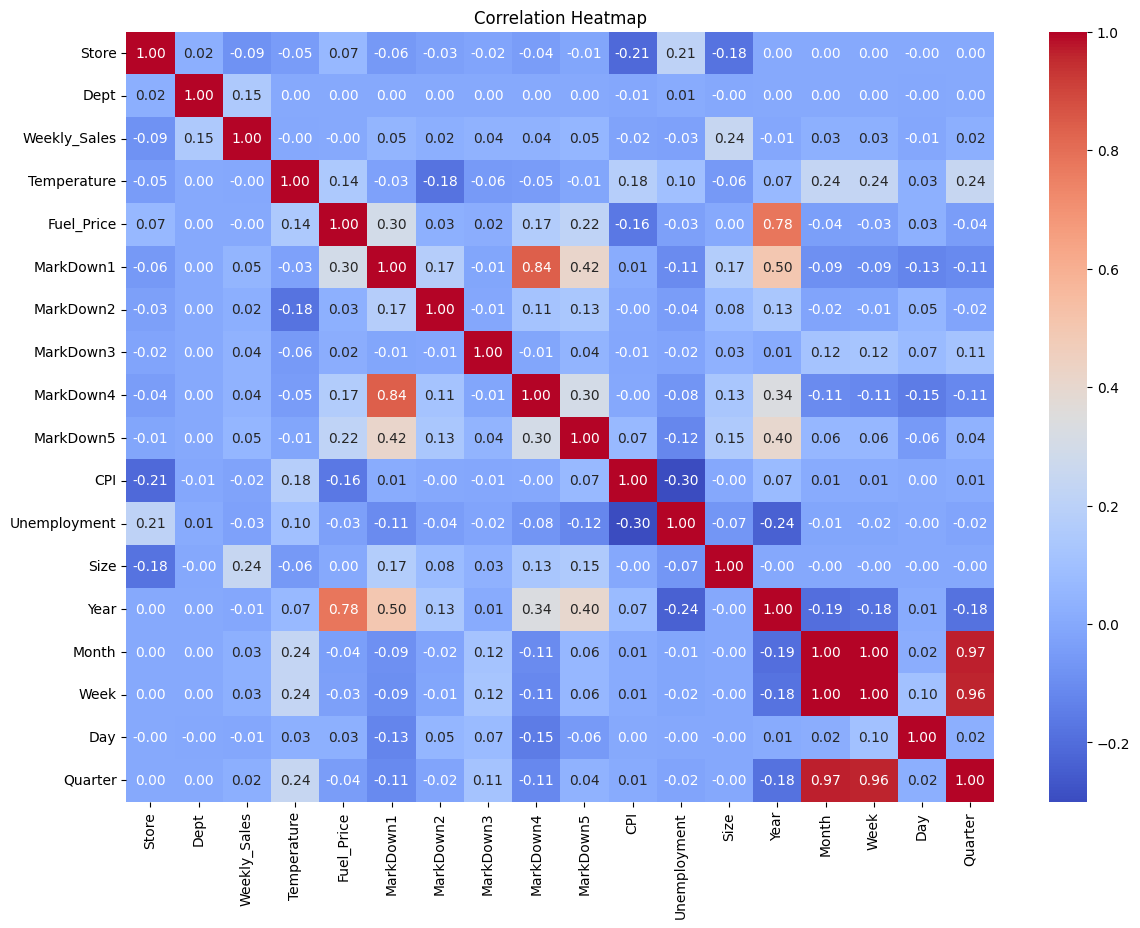

In [40]:
plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()

In [41]:
features_ml = [
    "Store",
    "Dept",
    "Temperature",
    "Fuel_Price",
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5",
    "CPI",
    "Unemployment",
    "Size",
    "Year",
    "Month",
    "Week",
    "Day",
    "Quarter",
    "IsHoliday",
    "Type"
]

X = df[features_ml]
y = df["Weekly_Sales"]

In [42]:
X = df[features_ml]
y = df["Weekly_Sales"]


In [43]:
X = pd.get_dummies(X, columns=["Type"], drop_first=True)

In [44]:
X["IsHoliday"] = X["IsHoliday"].astype(int)

In [45]:
print("Number of features:", X.shape[1])
print(X.head())

Number of features: 20
   Store  Dept  Temperature  Fuel_Price  MarkDown1  MarkDown2  MarkDown3  \
0      1     1        42.31       2.572        0.0        0.0        0.0   
1      1     1        38.51       2.548        0.0        0.0        0.0   
2      1     1        39.93       2.514        0.0        0.0        0.0   
3      1     1        46.63       2.561        0.0        0.0        0.0   
4      1     1        46.50       2.625        0.0        0.0        0.0   

   MarkDown4  MarkDown5         CPI  Unemployment    Size  Year  Month  Week  \
0        0.0        0.0  211.096358         8.106  151315  2010      2     5   
1        0.0        0.0  211.242170         8.106  151315  2010      2     6   
2        0.0        0.0  211.289143         8.106  151315  2010      2     7   
3        0.0        0.0  211.319643         8.106  151315  2010      2     8   
4        0.0        0.0  211.350143         8.106  151315  2010      3     9   

   Day  Quarter  IsHoliday  Type_B  Typ

In [46]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

df = df.sort_values("Date").reset_index(drop=True)

features_ml = [
    "Store",
    "Dept",
    "Temperature",
    "Fuel_Price",
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5",
    "CPI",
    "Unemployment",
    "Size",
    "Year",
    "Month",
    "Week",
    "Day",
    "Quarter",
    "IsHoliday",
    "Type"
]

X = df[features_ml].copy()

X = pd.get_dummies(X, columns=["Type"], drop_first=True)

X["IsHoliday"] = X["IsHoliday"].astype(int)

y = df["Weekly_Sales"]

split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training data: (337256, 20)
Testing data: (84314, 20)
Training target: (337256,)
Testing target: (84314,)


In [47]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)
print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [48]:
y_pred1 = model.predict(X_test_scaled)
print("Predictions generated successfully")
print("Number of predictions:", len(y_pred1))

Predictions generated successfully
Number of predictions: 84314


In [49]:
mae_lr = mean_absolute_error(y_test, y_pred1)
mse_lr = mean_squared_error(y_test, y_pred1)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred1)

print("Linear Regression Results")
print("-------------------------")
print("MAE  :", mae_lr)
print("MSE  :", mse_lr)
print("RMSE :", rmse_lr)
print("R²   :", r2_lr)

Linear Regression Results
-------------------------
MAE  : 14553.10118059765
MSE  : 436303644.1052965
RMSE : 20887.882709965997
R²   : 0.09419163948923659


In [50]:
dt_model = DecisionTreeRegressor(
    max_depth=15,
    min_samples_leaf=5,
    random_state=42
)

In [51]:
dt_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with `

In [52]:
y_pred2 = dt_model.predict(X_test)

In [53]:
mae_dt = mean_absolute_error(y_test, y_pred2)
mse_dt = mean_squared_error(y_test, y_pred2)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred2)

print("Decision Tree Regression Results")
print("--------------------------------")
print("MAE  :", mae_dt)
print("MSE  :", mse_dt)
print("RMSE :", rmse_dt)
print("R²   :", r2_dt)

Decision Tree Regression Results
--------------------------------
MAE  : 2470.9395451370033
MSE  : 26107564.959069632
RMSE : 5109.556238957512
R²   : 0.9457981822246805


In [54]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree"
    ],
    "MAE": [
        mae_lr,
        mae_dt
    ],
    "RMSE": [
        rmse_lr,
        rmse_dt
    ],
    "R²": [
        r2_lr,
        r2_dt
    ]
})
results

,Model,MAE,RMSE,R²
0,Linear Regression,14553.101181,20887.882710,0.094192
1,Decision Tree,2470.939545,5109.556239,0.945798


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max